# Option A: environmental-state clustering with K-means

This notebook clusters only the environmental conditions used to define offshore fatigue load cases. The structural response or fatigue damage is **not** used to form the clusters. Each cluster becomes one representative environmental state, weighted by its observed occurrence probability.

Wind direction is represented by its sine and cosine so that directions close to 0/360 degrees remain close in feature space.

In [7]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path(r"C:\Users\natal\Downloads\NREL_Trainset40000.mat")

with h5py.File(DATA_PATH, "r") as data_file:

    environmental_data = pd.DataFrame(
        {
            "wind_speed": np.asarray(data_file["Vw_mean"][:]).ravel(),
            "wave_height": np.asarray(data_file["Hs"][:]).ravel(),
            "wave_period": np.asarray(data_file["Tp"][:]).ravel(),
            "wind_direction": np.asarray(data_file["Wdir_mean"][:]).ravel(),
        }
    ).dropna()

environmental_data.head(), environmental_data.describe()


(   wind_speed  wave_height  wave_period  wind_direction
 0   13.304187     2.091505     6.528694       54.180633
 1   12.515495     1.010707     5.239104        2.988310
 2   18.123550     2.374400     6.942648     -106.203217
 3   14.646915     1.896751     7.286088      -95.430500
 4    5.768203     0.958752     8.077229     -106.463000,
          wind_speed   wave_height   wave_period  wind_direction
 count  39831.000000  39831.000000  39831.000000    39831.000000
 mean       9.417837      1.215490      6.046861        3.907655
 std        4.636043      0.781736      1.211756       87.548951
 min        0.622134      0.000158      2.512328     -163.399167
 25%        5.884484      0.634355      5.175157      -76.089912
 50%        8.937497      1.057086      5.984525       16.302556
 75%       12.405491      1.615534      6.847704       72.704842
 max       31.988117      6.170929     12.184751      162.880667)

## Prepare the clustering features

K-means uses Euclidean distance, so the environmental variables are standardised first. The direction is converted to two periodic coordinates; the original direction is retained for reporting.

In [5]:
direction_rad = np.deg2rad(environmental_data["wind_direction"] % 360.0)
environmental_data["wind_direction_sin"] = np.sin(direction_rad)
environmental_data["wind_direction_cos"] = np.cos(direction_rad)

feature_columns = [
    "wind_speed",
    "wave_height",
    "wave_period",
    "wind_direction_sin",
    "wind_direction_cos",
]
scaler = StandardScaler()
features = scaler.fit_transform(environmental_data[feature_columns])

## Select the number of environmental states

The silhouette score provides a reproducible diagnostic for a practical range of `k`. The selected value is a screening choice, not a substitute for checking whether every state is physically meaningful for the fatigue study.

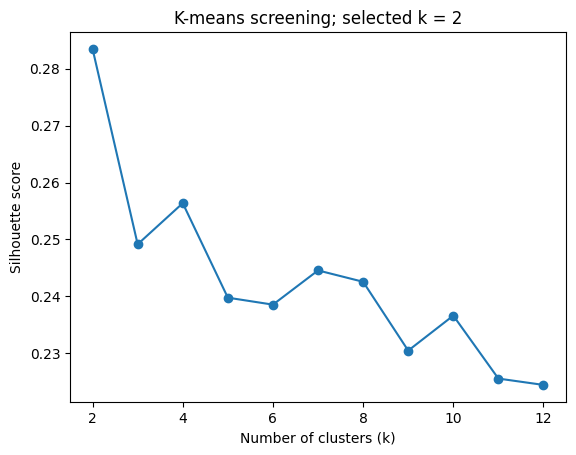

,k,silhouette
0,2,0.283488
1,3,0.249141
2,4,0.256366
3,5,0.239751
4,6,0.238526
5,7,0.244544
6,8,0.242544
7,9,0.230444
8,10,0.236597
9,11,0.225527


In [6]:
candidate_k = range(2, min(12, len(environmental_data) - 1) + 1)
silhouette_scores = []

for k in candidate_k:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(features)
    silhouette_scores.append(silhouette_score(features, labels))

selection = pd.DataFrame({"k": list(candidate_k), "silhouette": silhouette_scores})
selected_k = int(selection.loc[selection["silhouette"].idxmax(), "k"])

ax = selection.plot(x="k", y="silhouette", marker="o", legend=False)
ax.set(xlabel="Number of clusters (k)", ylabel="Silhouette score")
ax.set_title(f"K-means screening; selected k = {selected_k}")
plt.show()
selection


## Fit K-means and create representative fatigue states

The occurrence probability is the fraction of records in each state. Use these probabilities when combining fatigue damage from the representative states.

In [8]:
kmeans = KMeans(n_clusters=selected_k, n_init=50, random_state=42)
environmental_data["cluster"] = kmeans.fit_predict(features)

centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_), columns=feature_columns
)
centers["wind_direction"] = (
    np.rad2deg(
        np.arctan2(centers["wind_direction_sin"], centers["wind_direction_cos"])
    )
    % 360.0
)
centers["occurrence_count"] = environmental_data["cluster"].value_counts().sort_index()
centers["occurrence_probability"] = centers["occurrence_count"] / len(environmental_data)
representative_states = centers[
    ["wind_speed", "wave_height", "wave_period", "wind_direction", "occurrence_count", "occurrence_probability"]
].sort_values("wind_speed").reset_index(drop=True)

representative_states


,wind_speed,wave_height,wave_period,wind_direction,occurrence_count,occurrence_probability
0,7.221961,0.817969,5.599468,331.976794,27534,0.691271
1,14.343271,2.107146,7.050379,61.601800,12297,0.308729


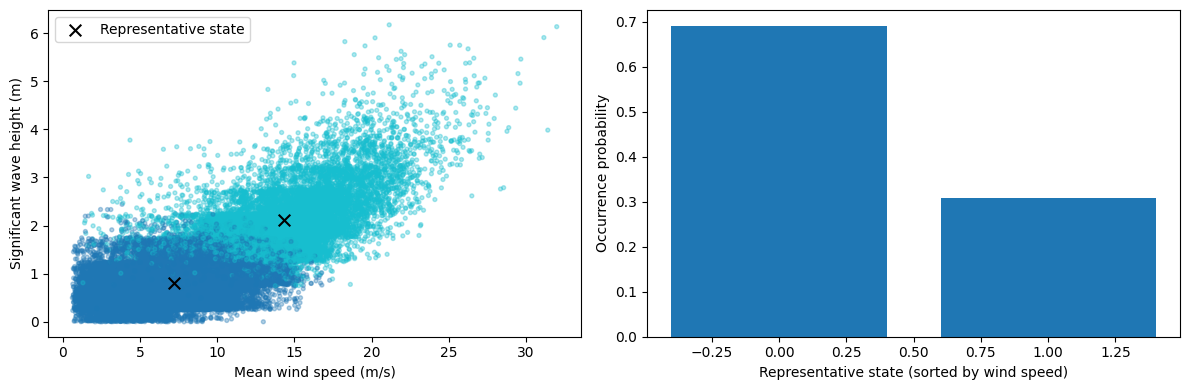

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(
    environmental_data["wind_speed"],
    environmental_data["wave_height"],
    c=environmental_data["cluster"],
    s=8,
    alpha=0.35,
    cmap="tab10",
)
axes[0].scatter(
    representative_states["wind_speed"],
    representative_states["wave_height"],
    c="black",
    marker="x",
    s=70,
    label="Representative state",
)
axes[0].set(xlabel="Mean wind speed (m/s)", ylabel="Significant wave height (m)")
axes[0].legend()

axes[1].bar(
    np.arange(len(representative_states)),
    representative_states["occurrence_probability"],
)
axes[1].set(
    xlabel="Representative state (sorted by wind speed)",
    ylabel="Occurrence probability",
)
plt.tight_layout()
plt.show()

## How to use the states in the fatigue study

Run the fatigue/load model once for each row in `representative_states`. Multiply each state damage rate by its `occurrence_probability` and sum the weighted contributions. Keep the table and the selected `k` with the study results so the environmental discretisation is traceable.

In [ ]:
output_path = Path("representative_environmental_states_kmeans.csv")
representative_states.to_csv(output_path, index=False)
print(f"Saved {len(representative_states)} representative states to {output_path}")
